# alftrade Demo

A pedagogical **A-share low-frequency cross-sectional trading system** (daily signal frequency) that mirrors the layered architecture of `hftrade` but adapts every layer to the multi-stock daily setting.

**Architecture:**
```
DailyBar[s]  →  FactorCalculator[s].update(bar)         (per-stock rolling state)
                     ↓
              cross-sectional standardization (z-score within universe)
                     ↓
              TradingEngine.on_cross_section(date, bars) → {symbol: [Signal]}
                     ↓
              SignalAggregator.aggregate_all()           → {symbol: CompositeSignal}
                     ↓
              PortfolioManager.decide() — rank top-N, target weights, rebalance
                   ↓                ↓
            RiskManager        RiskManager
            .check_pre_trade() .check_post_bar()
              (T+1 / limit /    (stop-loss / drawdown /
               lot / conc.)      daily-loss)
                ↓                    ↓
              [Trade] → Portfolio.apply_trade() → PnL
```

**A-share specifics modelled:**
- Long-only (no shorting)
- T+1 settlement (buys locked for one trading day)
- ±10% daily price-limit (reject buys at limit-up, sells at limit-down)
- 100-share board lot (buys rounded to multiples of 100)
- Transaction costs: commission (2.5 bps both ways, 5-yuan min) + stamp duty (10 bps on sells)
- Cross-sectional Fama-MacBeth Ridge calibration

**Sections:**
- Part I (§1–§7): Factor computation, cross-sectional signals, Fama-MacBeth calibration, factor profiling
- Part II (§8–§11): Portfolio rebalancing, equity curve, A-share risk controls, full calibrated pipeline


In [23]:
import numpy as np
import matplotlib.pyplot as plt

from alftrade import (
    DailyBar, StockUniverse, generate_simulated_market,
    FactorCalculator, FACTOR_NAMES,
    Signal, TradingEngine,
    Position, Trade, Portfolio, CostModel, CompositeSignal,
    SignalAggregator, PortfolioManager,
    RiskManager, RiskConfig,
    CalibrationResult, FactorCalibrator,
    FactorProfile, ModelProfile, FactorProfiler,
)

plt.rcParams["figure.dpi"] = 110
np.random.seed(42)
print("alftrade ready —", len(FACTOR_NAMES), "factors available")

alftrade ready — 10 factors available


---

# Part I — Factors & Signals

## 1. Direct Factor Computation

The `FactorCalculator` maintains per-stock rolling state (price/volume windows, Wilder RSI & ATR). Feed it one `DailyBar` at a time and it returns the 10 daily factors. Unlike `hftrade`'s C++ calculator, all factors are **already stationary** (returns, ratios, bounded indicators) — no price levels leak in.

In [24]:
calc = FactorCalculator()

# Build a synthetic bar: close=10.5, prev_close=10.0
from alftrade.data import compute_limit_prices
up, dn = compute_limit_prices(10.0, 0.10)
bar = DailyBar(
    date=20200101, symbol="000001.SZ",
    open=10.05, high=10.60, low=10.00, close=10.50,
    volume=1_200_000, amount=12_600_000,
    prev_close=10.0, limit_up_price=up, limit_down_price=dn,
    total_shares=500_000_000,
)

factors = calc.update(bar)
for name in FACTOR_NAMES:
    print(f"  {name:<16s} = {factors[name]:+.6f}")

  daily_return     = +0.050000
  overnight_return = +0.005000
  intraday_return  = +0.044776
  momentum_5d      = +0.000000
  momentum_20d     = +0.000000
  ma_dev_20        = +0.000000
  volatility_20d   = +0.000000
  volume_ratio     = +1.000000
  rsi_14           = +0.000000
  atr_pct_14       = +0.057143


### Factor definitions

| Factor | Formula | Interpretation |
|--------|---------|---------------|
| `daily_return` | (close − prev_close) / prev_close | Close-to-close return |
| `overnight_return` | (open − prev_close) / prev_close | Overnight gap |
| `intraday_return` | (close − open) / open | In-session return |
| `momentum_5d` | (close − close[t-5]) / close[t-5] | 5-day reversal signal |
| `momentum_20d` | (close − close[t-20]) / close[t-20] | 20-day momentum |
| `ma_dev_20` | (close − SMA20) / SMA20 | Deviation from 20d average |
| `volatility_20d` | std(daily_return, 20) | 20-day return volatility |
| `volume_ratio` | volume / SMA(volume, 20) | Relative turnover |
| `rsi_14` | (RSI14 − 50) / 50, ∈ [−1, +1] | Rescaled Wilder RSI |
| `atr_pct_14` | ATR14 / close | Normalized average true range |

## 2. Streaming Daily Bars — Factor Evolution

Feed 80 days of one stock's bars through a calculator and watch the rolling factors fill in.

In [25]:
# Generate a small panel and pick one stock to inspect.
bars_by_date, universe = generate_simulated_market(n_stocks=5, n_days=120, seed=3)
dates = sorted(bars_by_date)
sym = universe.symbols[0]

calc = FactorCalculator()
history = {k: [] for k in FACTOR_NAMES}
closes = []

for d in dates:
    f = calc.update(bars_by_date[d][sym])
    closes.append(bars_by_date[d][sym].close)
    for k in FACTOR_NAMES:
        history[k].append(f[k])

print(f"Tracked {sym} over {len(dates)} days; close went "
      f"{closes[0]:.2f} → {closes[-1]:.2f}")

Tracked 600000.SH over 120 days; close went 34.51 → 55.05


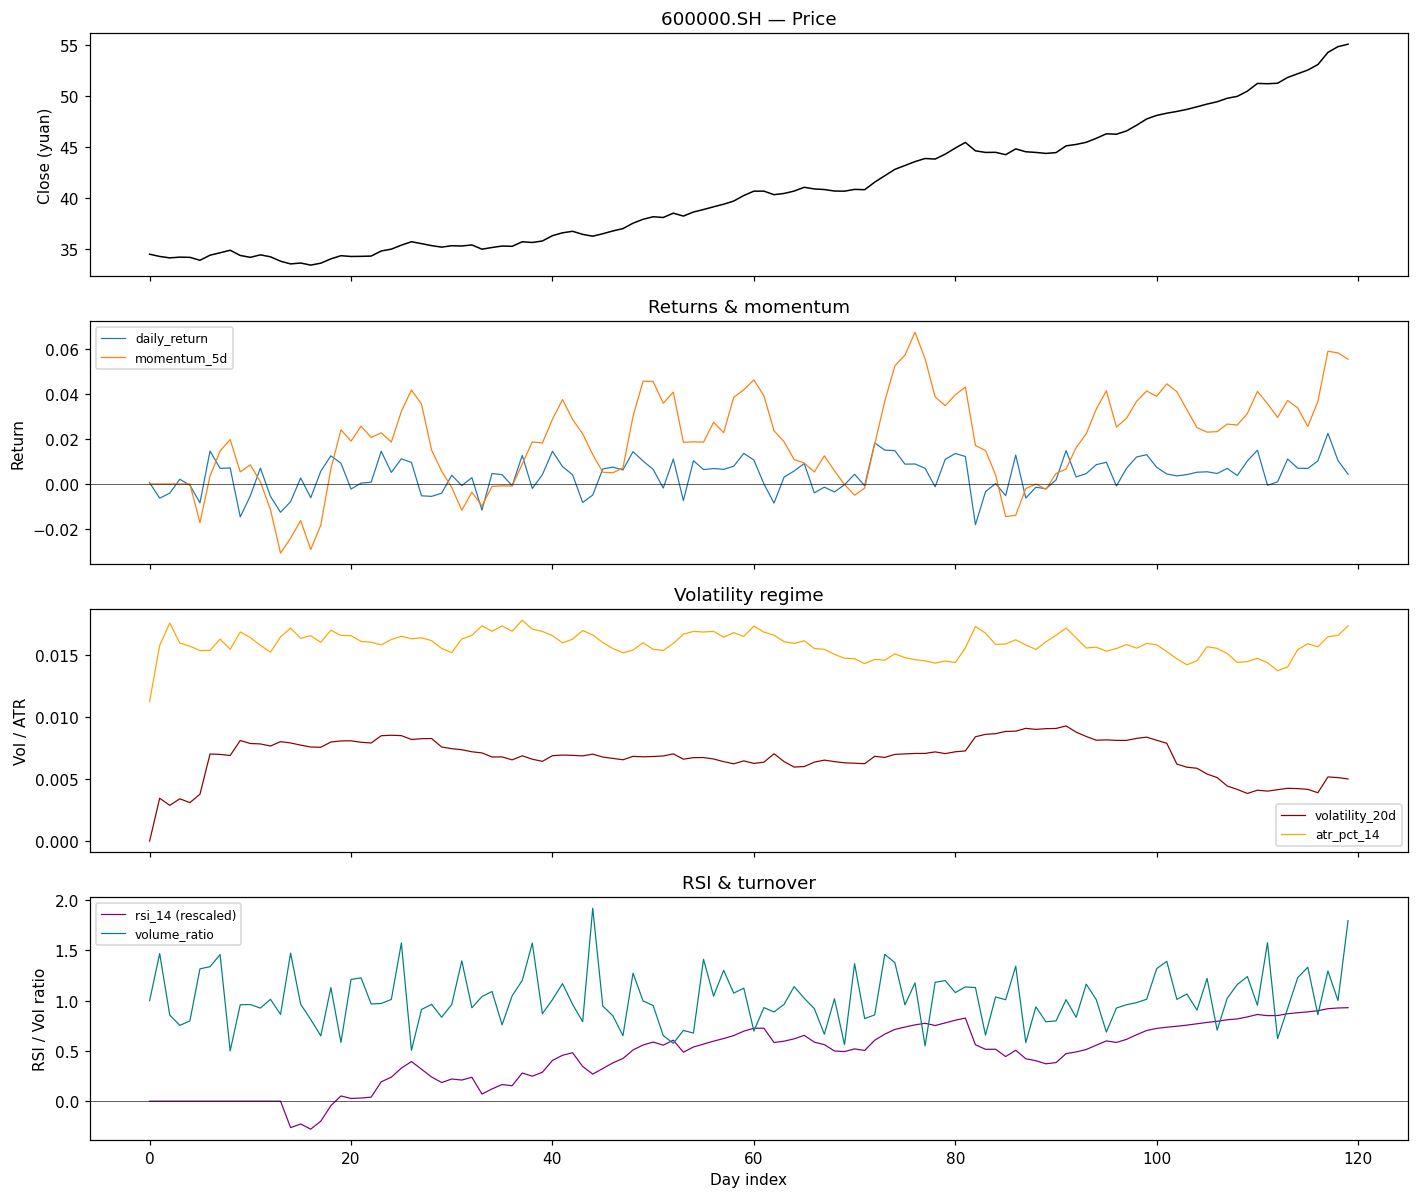

In [26]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)

x = range(len(dates))
axes[0].plot(x, closes, linewidth=1.0, color="black")
axes[0].set_ylabel("Close (yuan)")
axes[0].set_title(f"{sym} — Price")

axes[1].plot(x, history["daily_return"], linewidth=0.8, label="daily_return")
axes[1].plot(x, history["momentum_5d"], linewidth=0.8, label="momentum_5d")
axes[1].axhline(0, color="k", linewidth=0.4)
axes[1].set_ylabel("Return")
axes[1].set_title("Returns & momentum")
axes[1].legend(fontsize=8)

axes[2].plot(x, history["volatility_20d"], linewidth=0.8, color="darkred", label="volatility_20d")
axes[2].plot(x, history["atr_pct_14"], linewidth=0.8, color="orange", label="atr_pct_14")
axes[2].set_ylabel("Vol / ATR")
axes[2].set_title("Volatility regime")
axes[2].legend(fontsize=8)

axes[3].plot(x, history["rsi_14"], linewidth=0.8, color="purple", label="rsi_14 (rescaled)")
axes[3].plot(x, history["volume_ratio"], linewidth=0.8, color="teal", label="volume_ratio")
axes[3].axhline(0, color="k", linewidth=0.4)
axes[3].set_ylabel("RSI / Vol ratio")
axes[3].set_xlabel("Day index")
axes[3].set_title("RSI & turnover")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Cross-Sectional Standardization

A-share daily strategies compare stocks *to each other* on each date, not to their own history. The engine z-scores every factor **within the day's universe** before applying calibration β — this removes day-to-day scale drift and makes β interpretable as "per-1σ cross-sectional exposure".

The same standardization must be applied identically in offline calibration (`fit`) and online inference (`_calibrated_signals`).

In [27]:
# Show one date's raw factors vs standardized
engine = TradingEngine()
d = dates[-1]
cs = engine.build_cross_section(d, bars_by_date[d])

print(f"Date {d}: {len(cs.symbols)} stocks")
print()
print(f"  {'Stock':<12s}  raw momentum_5d   z(momentum_5d)")
print(f"  {'-'*12}  {'-'*16}  {'-'*16}")
for i, sym in enumerate(cs.symbols):
    raw = cs.factors_by_symbol[sym]["momentum_5d"]
    z = cs.z_matrix[i, FACTOR_NAMES.index("momentum_5d")]
    print(f"  {sym:<12s}  {raw:+.6f}        {z:+.4f}")

Date 20200220: 5 stocks

  Stock         raw momentum_5d   z(momentum_5d)
  ------------  ----------------  ----------------
  600000.SH     +0.000000        +0.0000
  600001.SH     +0.000000        +0.0000
  600002.SH     +0.000000        +0.0000
  600003.SH     +0.000000        +0.0000
  600004.SH     +0.000000        +0.0000


## 4. Signal Generation — Raw Mode

In **raw mode** (no calibration), the engine applies per-factor threshold rules. Each factor that exceeds its threshold fires one `Signal`. This is useful for inspection and as a baseline before calibration.

Long-only convention: a positive factor reading → `LONG` (direction=+1); a negative reading → `FLAT` (direction=0), never `SHORT`.

In [28]:
engine_raw = TradingEngine(raw_thresholds={
    "momentum_5d": 0.02,
    "rsi_14": 0.30,
    "ma_dev_20": 0.02,
})

out = engine_raw.on_cross_section(d, bars_by_date[d])
print(f"Date {d}: {len(out)} stocks have signals")
print()
for sym, sigs in list(out.items())[:6]:
    for s in sigs:
        print(f"  {s}")

Date 20200220: 0 stocks have signals



---

## 5. Factor Calibration — Fama-MacBeth Cross-Sectional Ridge

### Why Fama-MacBeth (not one pooled regression)?

A pooled regression stacks every (date, stock) pair and runs one Ridge. Its standard errors assume residuals are independent across dates — which they are not. Fama-MacBeth (1973) fixes this:

1. Run a **separate** cross-sectional Ridge regression per date: β_t = (X_t'X_t + αI)⁻¹ X_t'y_t
2. Report β̄ = mean_t(β_t) and t = mean_t(β_t) / (std_t(β_t) / √T)

The time-series variation of β_t itself drives significance — the standard estimator in equity factor research.

### Two-phase usage (mirrors hftrade)

**Phase 1:** walk historical bars, pair each date's factors with the realized N-day forward return.
**Phase 2:** fit and hand the result to the engine + aggregator.

In [29]:
# Generate a larger panel for calibration
bars_full, uni_full = generate_simulated_market(n_stocks=30, n_days=250, seed=7)
dates_full = sorted(bars_full)
split = dates_full[:-30]   # train on first 220 days

# Dedicated offline engine (its per-symbol calculators persist across dates)
offline_engine = TradingEngine()
calibrator = FactorCalibrator(horizon=5, alpha=1.0, min_samples=50, min_dates=10)

for d in split:
    cs = offline_engine.build_cross_section(d, bars_full[d])
    calibrator.collect(d, cs, bars_full)

print(f"Collected {calibrator.num_samples} (date, stock) pairs across {calibrator.num_dates} dates")
print(f"Ready to fit: {calibrator.ready}")

Collected 6450 (date, stock) pairs across 215 dates
Ready to fit: True


In [30]:
result = calibrator.fit(method="fama_macbeth")
print(result)

CalibrationResult(horizon=5, method=fama_macbeth, alpha=1.0, n=6450, T=215, R²=0.3246), date=2026-07-07T15:30:35.055474+00:00
  Factor                 Beta   t-stat       IC       IR
  ---------------- ---------- -------- -------- --------
  daily_return       -0.00053    -1.94   0.0211    0.109
  overnight_return   -0.00038    -0.98  -0.0155   -0.097
  intraday_return    -0.00043    -1.67   0.0232    0.119
  momentum_5d        -0.00072    -1.13   0.0985    0.514
  momentum_20d       -0.00156    -1.88   0.1602    0.826
  ma_dev_20           0.00108     1.07   0.1574    0.858
  volatility_20d     -0.00704    -9.23  -0.2847   -1.406
  volume_ratio        0.00070     1.59   0.0277    0.147
  rsi_14              0.00178     1.98   0.1799    1.007
  atr_pct_14         -0.00195    -2.32  -0.2521   -1.282


### Reading the calibration output

| Column | Meaning | Good value |
|--------|---------|------------|
| `Beta` | FM-averaged cross-sectional Ridge coefficient | Large \|β\| with correct sign |
| `t-stat` | FM t-statistic = β̄ / (std(β_t)/√T) | \|t\| > 2 is conventionally significant |
| `IC` | Pooled Pearson corr(factor, y) | \|IC\| > 0.03 is live-tradeable in A-shares |
| `IR` | Information Ratio = mean(IC_t) / std(IC_t) | \|IR\| > 0.5 is a consistent factor |

The simulator embeds a **negative volatility loading** (low-vol anomaly) and **negative 5-day momentum** (short-term reversal) — both classic A-share effects. Check that the calibrator recovers them with the correct sign and high significance.

---

## 6. Factor Profiler — Which factors are actually good?

While `CalibrationResult` gives β and IC for *building* signals, `FactorProfiler` evaluates factor **quality**: quantile returns, monotonicity, turnover, coverage, and partial R² contribution.

In [31]:
profiler = FactorProfiler.from_calibrator(calibrator, n_quantiles=5)
model_profile = profiler.profile()
print(model_profile)

ModelProfile(n=6450, T=215, k=10, model_IC=0.2905, model_mono=1.0000, L−S=0.02746)
  Factor                 Beta    t-stat         IC      IR       L−S   turn    mono
  ---------------- ---------- ---------    ------- ------- --------- ------ -------
  daily_return     β=  -0.00053 t=  -1.94    IC= 0.0211 IR=  0.109 L−S= 0.00072 turn= 0.340 mono=  0.400
  overnight_return β=  -0.00038 t=  -0.98    IC=-0.0155 IR= -0.097 L−S=-0.00317 turn= 0.342 mono= -0.700
  intraday_return  β=  -0.00043 t=  -1.67    IC= 0.0232 IR=  0.119 L−S= 0.00168 turn= 0.341 mono=  0.400
  momentum_5d      β=  -0.00072 t=  -1.13    IC= 0.0985 IR=  0.514 L−S= 0.00879 turn= 0.146 mono=  0.700
  momentum_20d     β=  -0.00156 t=  -1.88    IC= 0.1602 IR=  0.826 L−S= 0.01305 turn= 0.061 mono=  0.900
  ma_dev_20        β=   0.00108 t=   1.07    IC= 0.1574 IR=  0.858 L−S= 0.01550 turn= 0.088 mono=  1.000
  volatility_20d   β=  -0.00704 t=  -9.23*** IC=-0.2847 IR= -1.406 L−S=-0.02738 turn= 0.045 mono= -1.000
  volume_ratio

### Quantile analysis — visualizing factor monotonicity

For a good cross-sectional factor, mean forward return should increase (or decrease) monotonically across quantiles sorted by factor value. The **long-short spread** (top − bottom quantile) is the single-number summary of a factor's payoff.

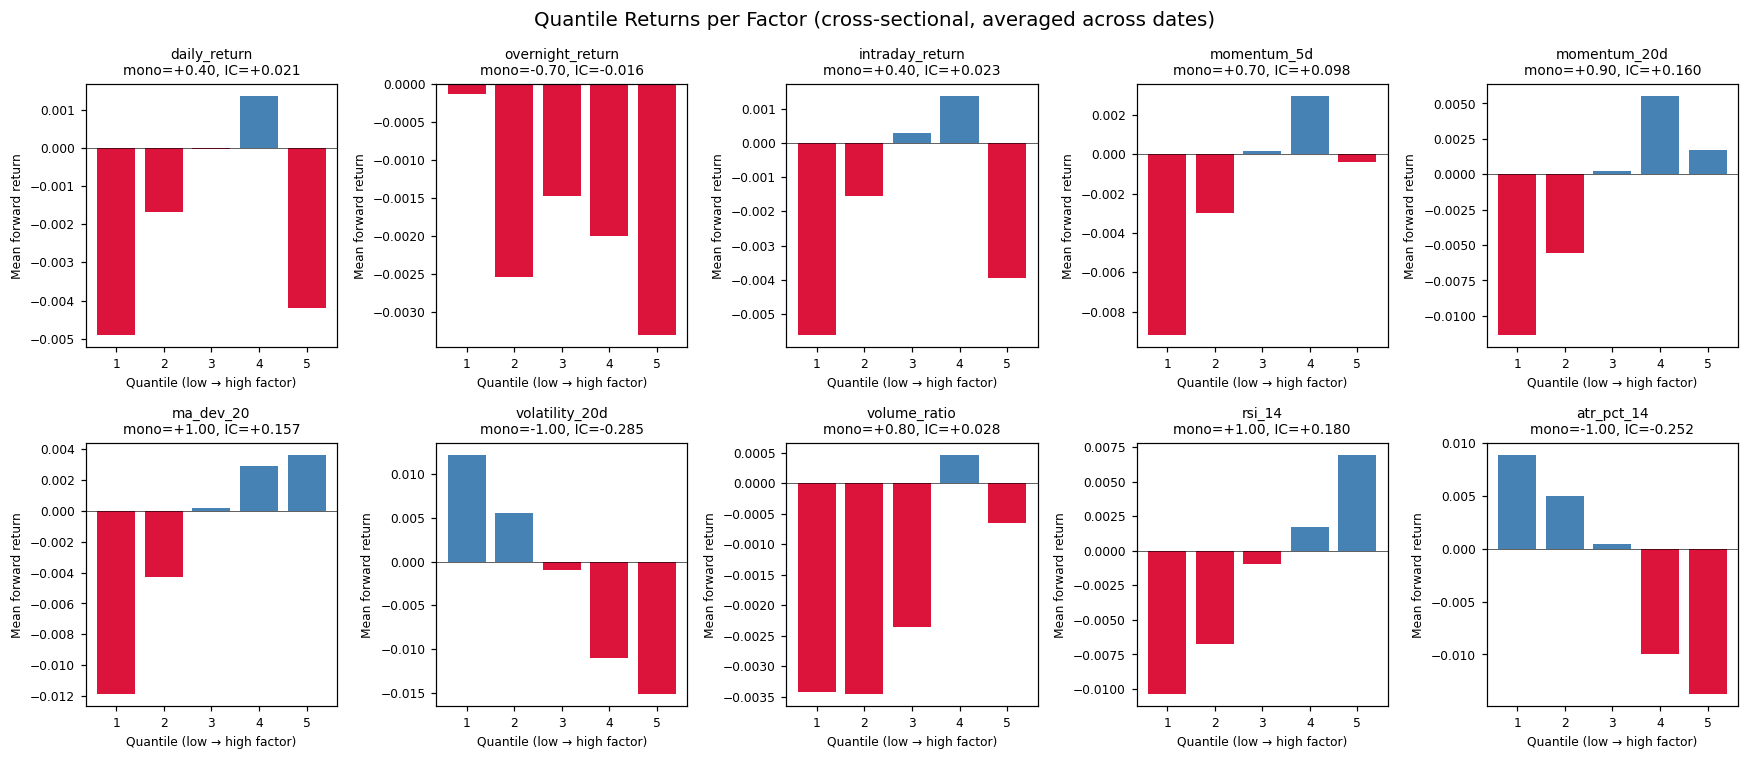

In [32]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, fp in zip(axes.flat, model_profile.factor_profiles):
    if fp.quantile_returns:
        qs = range(1, len(fp.quantile_returns) + 1)
        colors = ["crimson" if r < 0 else "steelblue" for r in fp.quantile_returns]
        ax.bar(qs, fp.quantile_returns, color=colors)
        ax.set_title(f"{fp.name}\nmono={fp.monotonicity:+.2f}, IC={fp.ic:+.3f}", fontsize=9)
        ax.set_xlabel("Quantile (low → high factor)", fontsize=8)
        ax.set_ylabel("Mean forward return", fontsize=8)
        ax.axhline(0, color="k", linewidth=0.4)
        ax.tick_params(labelsize=8)
    else:
        ax.set_visible(False)

plt.suptitle("Quantile Returns per Factor (cross-sectional, averaged across dates)", fontsize=13)
plt.tight_layout()
plt.show()

### Model-level monotonicity — does the model rank correctly?

The model predicts a forward return per stock: ŷ = Σ β_k · z(factor_k). A good model's predicted ranking should match actual returns across quantiles. `model_monotonicity` is the Spearman rank correlation between quantile index and mean actual return.

In [33]:
print(f"Model IC:            {model_profile.model_ic:+.4f}")
print(f"Model monotonicity:  {model_profile.model_monotonicity:+.4f}")
print(f"Long-short spread:   {model_profile.long_short_spread:+.5f}")
print()
print("Model quantile returns (low → high predicted return):")
for i, r in enumerate(model_profile.model_quantile_returns, 1):
    print(f"  Q{i}: {r:+.5f}")

Model IC:            +0.2905
Model monotonicity:  +1.0000
Long-short spread:   +0.02746

Model quantile returns (low → high predicted return):
  Q1: -0.01551
  Q2: -0.01068
  Q3: -0.00169
  Q4: +0.00650
  Q5: +0.01194


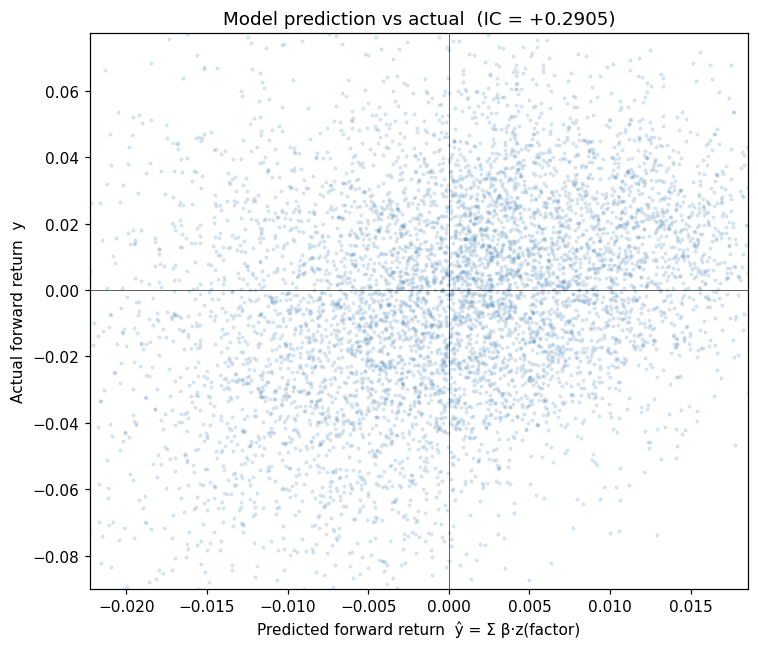

In [34]:
# y_pred vs y scatter with quantile overlay
betas = np.array([result.betas.get(n, 0.0) for n in FACTOR_NAMES])

# Rebuild the full panel of (z, y) to scatter
X_all = np.vstack([calibrator._by_date[d][0] for d in sorted(calibrator._by_date)])
y_all = np.concatenate([calibrator._by_date[d][1] for d in sorted(calibrator._by_date)])
y_pred = X_all @ betas

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_pred, y_all, s=3, alpha=0.15, color="steelblue")
ax.axhline(0, color="k", linewidth=0.4)
ax.axvline(0, color="k", linewidth=0.4)
ax.set_xlabel("Predicted forward return  ŷ = Σ β·z(factor)")
ax.set_ylabel("Actual forward return  y")
ax.set_title(f"Model prediction vs actual  (IC = {model_profile.model_ic:+.4f})")
lo, hi = np.percentile(y_pred, [1, 99])
ax.set_xlim(lo, hi)
ax.set_ylim(np.percentile(y_all, [1, 99]))
plt.tight_layout()
plt.show()

---

# Part II — Portfolio & Risk

## 8. From Signals to Portfolio

The `PortfolioManager` converts per-stock signals into a target portfolio:

1. **Aggregate** each stock's signals into one composite score.
2. **Rank** stocks by score; pick the top `n_holdings` with positive score.
3. **Assign target weights** (equal-weight or score-weighted).
4. **Generate trades**: sells first (free cash), then buys (capped by cash, rounded to board lot).
5. **Risk gate**: each trade passes through `RiskManager.check_pre_trade`.
6. **Post-bar monitor**: `check_post_bar` may force-close positions.

In [35]:
# Use the calibration result from §5
live_engine = TradingEngine(calibration=result)
aggregator = SignalAggregator(calibration=result)

pm = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=aggregator,
)

# Run the first held-out day
d0 = dates_full[-30]
sigs = live_engine.on_cross_section(d0, bars_full[d0])
trades = pm.decide(d0, bars_full[d0], sigs)

print(f"Date {d0}: {len(trades)} trades executed")
print()
for t in trades:
    print(f"  {t}")
print()
n_pos = sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0)
equity = pm.portfolio.mark_to_market(bars_full[d0])
print(f"Positions open: {n_pos}  |  Equity: {equity:,.0f}")

Date 20200321: 5 trades executed

  Trade(20200321 600001.SH OPEN qty=+7100 @ 28.00 cost=53.68 pnl=0.00 [REBALANCE])
  Trade(20200321 600004.SH OPEN qty=+8600 @ 23.05 cost=53.51 pnl=0.00 [REBALANCE])
  Trade(20200321 600020.SH OPEN qty=+13700 @ 14.59 cost=53.97 pnl=0.00 [REBALANCE])
  Trade(20200321 600014.SH OPEN qty=+6800 @ 29.06 cost=53.35 pnl=0.00 [REBALANCE])
  Trade(20200321 600006.SH OPEN qty=+4000 @ 49.97 cost=53.97 pnl=0.00 [REBALANCE])

Positions open: 5  |  Equity: 999,732


## 9. Equity Curve — Running the Full Pipeline Over Time

Walk the held-out 30 days through the calibrated pipeline and track equity, position count, and cash.

In [36]:
pm = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=SignalAggregator(calibration=result),
)
live_engine = TradingEngine(calibration=result)

held_out = dates_full[-30:]
equity_hist, cash_hist, npos_hist, realized_hist, unrealized_hist = [], [], [], [], []

# Per-date cross-sectional records for §9a/§9b visualizations:
#   score_matrix[t, i]  = predicted return of stock i on date t (NaN if suspended)
#   weight_matrix[t, i] = portfolio weight of stock i after rebalance on date t
all_syms = sorted(uni_full.symbols)
sym_idx = {s: i for i, s in enumerate(all_syms)}
score_matrix = np.full((len(held_out), len(all_syms)), np.nan)
weight_matrix = np.zeros((len(held_out), len(all_syms)))

for t, d in enumerate(held_out):
    sigs = live_engine.on_cross_section(d, bars_full[d])
    pm.decide(d, bars_full[d], sigs)

    # Record each stock's model predicted return (the "model" signal strength
    # with its sign), recovered from sigs.
    for sym, lst in sigs.items():
        s = lst[0]
        signed = s.strength if s.direction > 0 else -s.strength
        score_matrix[t, sym_idx[sym]] = signed

    # Record post-rebalance weights = qty * close / equity.
    eq = pm.portfolio.mark_to_market(bars_full[d])
    for sym, pos in pm.portfolio.positions.items():
        if pos.quantity > 0:
            weight_matrix[t, sym_idx[sym]] = pos.quantity * bars_full[d][sym].close / eq

    equity_hist.append(eq)
    cash_hist.append(pm.portfolio.cash)
    npos_hist.append(sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0))
    realized_hist.append(sum(p.realized_pnl for p in pm.portfolio.positions.values()))
    unrealized_hist.append(eq - pm.portfolio.cash - sum(
        p.realized_pnl for p in pm.portfolio.positions.values()))

print(f"Final equity:   {equity_hist[-1]:,.0f}")
print(f"Total return:   {(equity_hist[-1] / 1_000_000 - 1) * 100:+.2f}%")
print(f"Total trades:   {len(pm.trades)}")
print(f"Max positions:  {max(npos_hist)}")
print(f"Score matrix:   {score_matrix.shape}  (dates x stocks)")
print(f"Weight matrix:  {weight_matrix.shape}  (dates x stocks)")

Final equity:   1,102,084
Total return:   +10.21%
Total trades:   121
Max positions:  5
Score matrix:   (30, 30)  (dates x stocks)
Weight matrix:  (30, 30)  (dates x stocks)


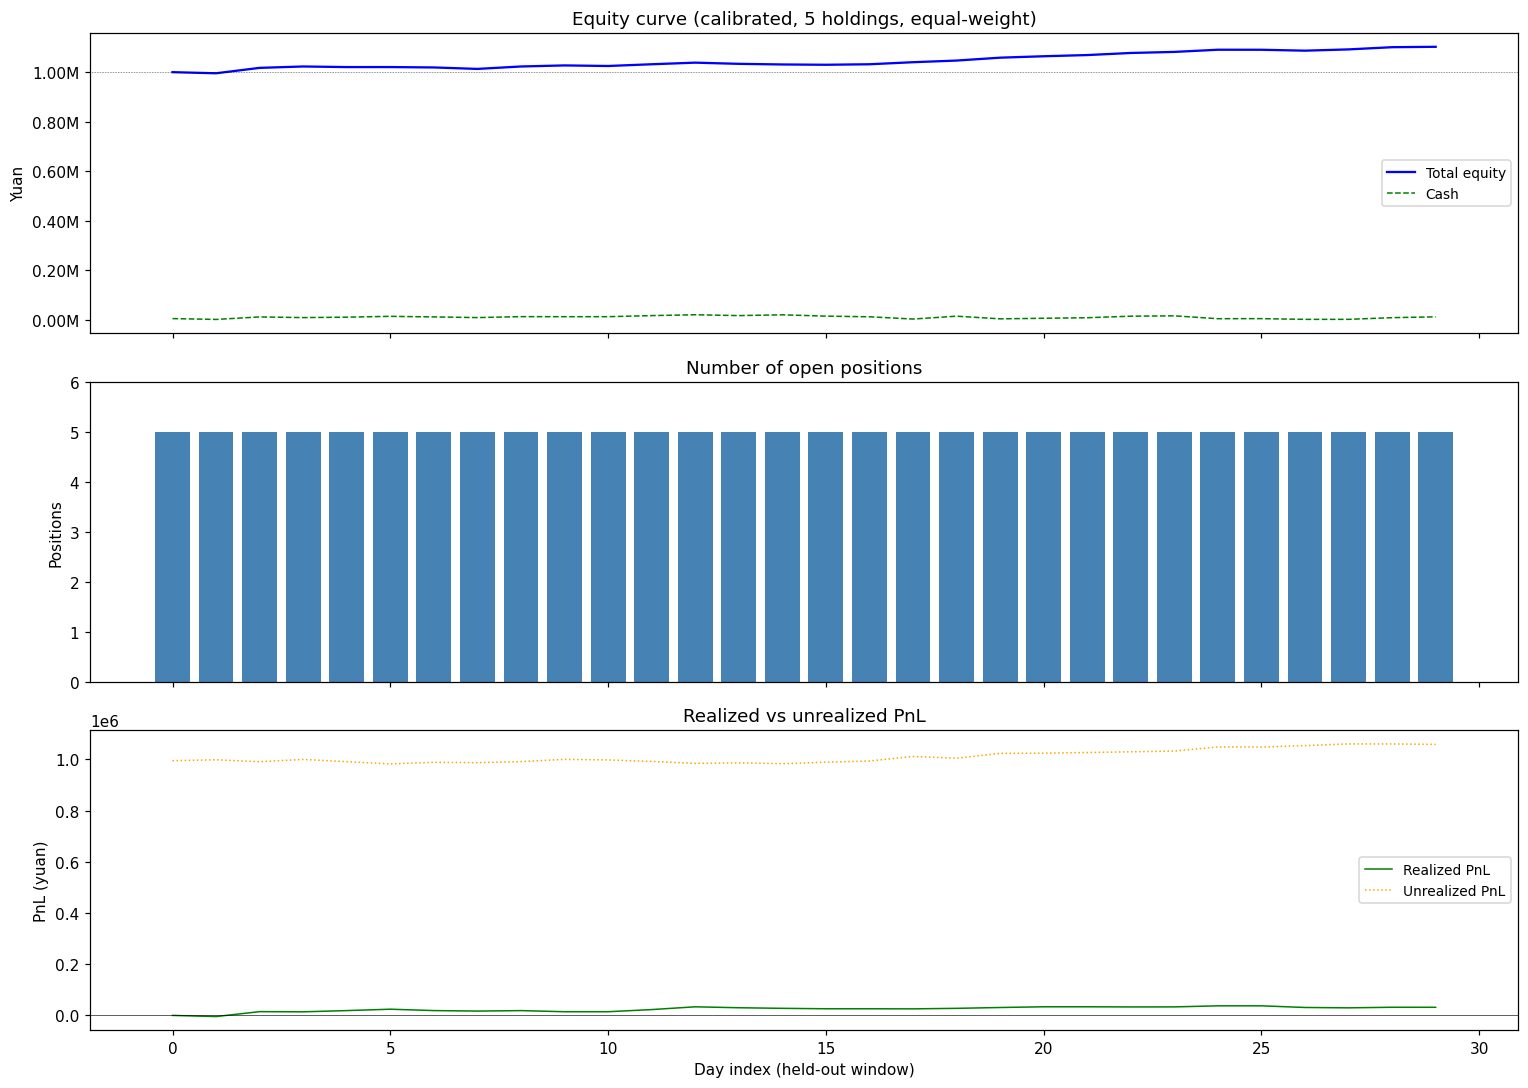

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
x = range(len(held_out))

axes[0].plot(x, equity_hist, linewidth=1.5, color="blue", label="Total equity")
axes[0].plot(x, cash_hist, linewidth=1.0, color="green", linestyle="--", label="Cash")
axes[0].axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
axes[0].set_ylabel("Yuan")
axes[0].set_title("Equity curve (calibrated, 5 holdings, equal-weight)")
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))

axes[1].bar(x, npos_hist, color="steelblue")
axes[1].set_ylabel("Positions")
axes[1].set_title("Number of open positions")
axes[1].set_ylim(0, max(npos_hist) + 1)

axes[2].plot(x, realized_hist, linewidth=1.0, color="green", label="Realized PnL")
axes[2].plot(x, unrealized_hist, linewidth=1.0, color="orange", linestyle=":", label="Unrealized PnL")
axes[2].axhline(0, color="k", linewidth=0.4)
axes[2].set_ylabel("PnL (yuan)")
axes[2].set_xlabel("Day index (held-out window)")
axes[2].set_title("Realized vs unrealized PnL")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 9a. Cross-Sectional Signal Heatmap

Each row is a stock, each column is a held-out date. Color = the model's predicted forward return (ŷ = Σ β·z) on that date. The dashed line marks the **top-5 boundary** each day — stocks above it are long candidates.

What to look for:
- **Persistent dark bands** = stocks the model consistently ranks high (low-turnover alpha).
- **Flickering cells near the boundary** = stocks that keep entering/exiting the top-5 (high turnover, less stable alpha).
- **Color flips** (blue↔red) = the model changes its mind about a stock's direction.

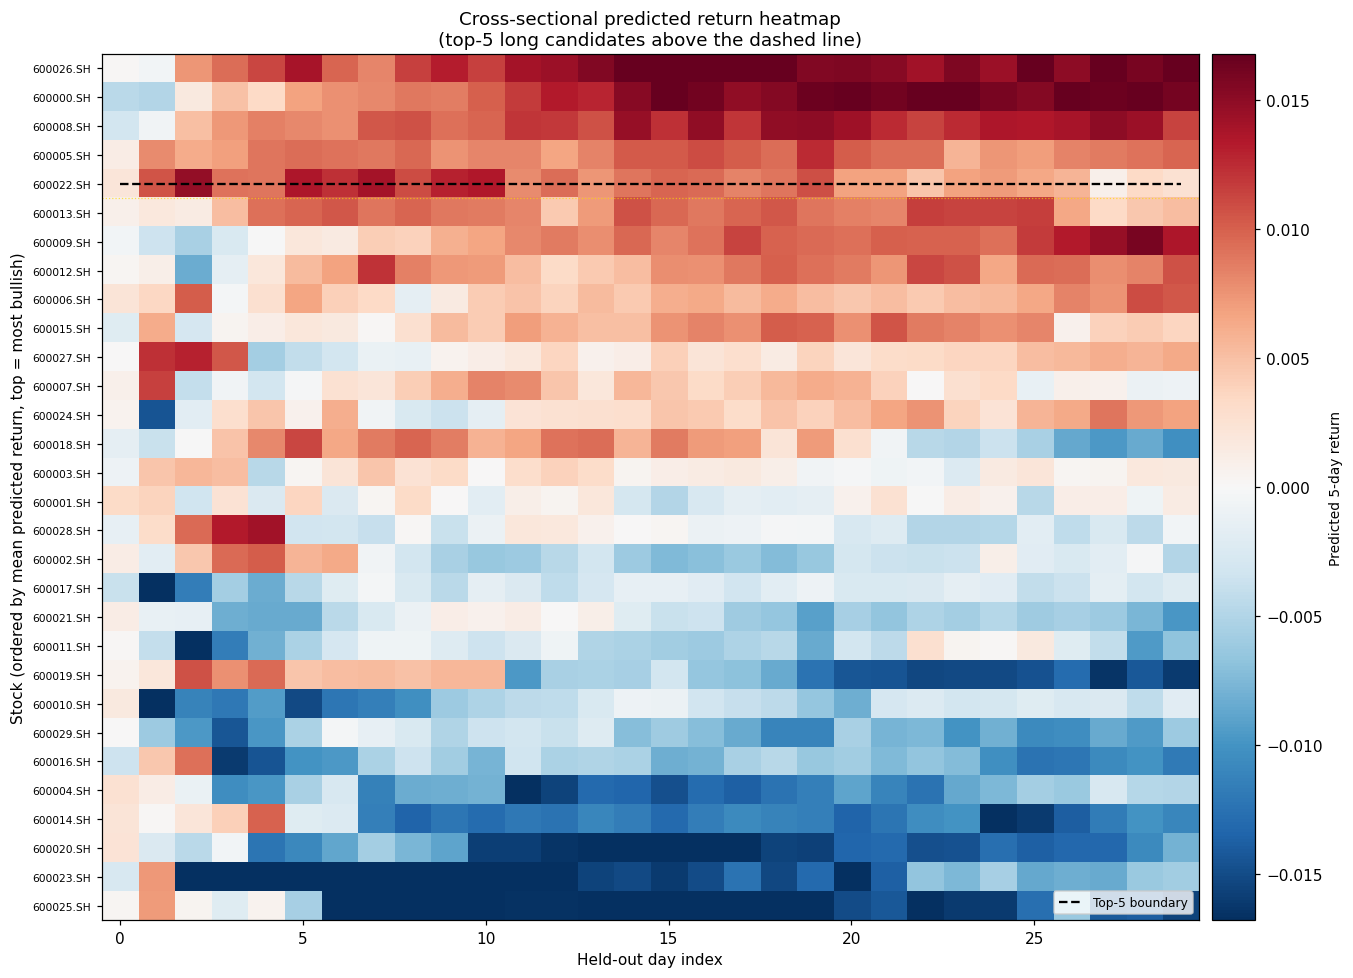

In [38]:
# Order stocks by their average predicted return (most bullish at top)
# so the heatmap reads naturally: top rows = long candidates, bottom = short.
mean_score = np.nanmean(score_matrix, axis=0)
order = np.argsort(-mean_score)  # descending
score_ordered = score_matrix[:, order]
syms_ordered = [all_syms[i] for i in order]

fig, ax = plt.subplots(figsize=(13, 9))
vmax = np.nanpercentile(abs(score_ordered), 95)
im = ax.imshow(score_ordered.T, aspect="auto", cmap="RdBu_r",
               vmin=-vmax, vmax=vmax, interpolation="nearest",
               extent=[-0.5, len(held_out) - 0.5, len(all_syms) - 0.5, -0.5])

# Draw the top-5 boundary: for each date, find the rank of the 5th-highest
# non-NAN score and mark it.
boundary_y = []
for t in range(len(held_out)):
    col = score_ordered[t]
    valid = ~np.isnan(col)
    if valid.sum() < 5:
        boundary_y.append(np.nan)
        continue
    # The 5th-highest valid score's row index (in the ordered frame).
    valid_rows = np.where(valid)[0]
    valid_scores = col[valid_rows]
    # Top-5 are the 5 lowest row indices among valid rows (since ordered desc).
    # Boundary = index of the 5th valid row.
    boundary_y.append(valid_rows[4])  # 0-indexed: rows 0..4 are top-5

ax.plot(range(len(held_out)), boundary_y, "k--", linewidth=1.5, label="Top-5 boundary")
ax.axhline(4.5, color="gold", linewidth=0.8, linestyle=":", alpha=0.7)

ax.set_yticks(range(len(syms_ordered)))
ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_ylabel("Stock (ordered by mean predicted return, top = most bullish)")
ax.set_xlabel("Held-out day index")
ax.set_title("Cross-sectional predicted return heatmap\n(top-5 long candidates above the dashed line)")
ax.legend(loc="lower right", fontsize=8)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Predicted 5-day return", fontsize=9)
plt.tight_layout()
plt.show()

## 9b. Position Occupancy Heatmap

Same axes as §9a, but color now = **actual portfolio weight** after each day's rebalance. White = not held; colored = held, with color intensity = weight.

Comparing this to §9a reveals the full signal→position chain:
- A cell that is **dark in §9a but white here** = the model liked the stock but it was blocked (cash short, lot rounding, or limit-up).
- A cell that is **light in §9a but colored here** = held over from a previous day (T+1 lock prevents same-day exit), even though the signal faded.
- **Vertical streaks** = stocks held for many consecutive days (low turnover).
- **Isolated cells** = one-day holds (high turnover).

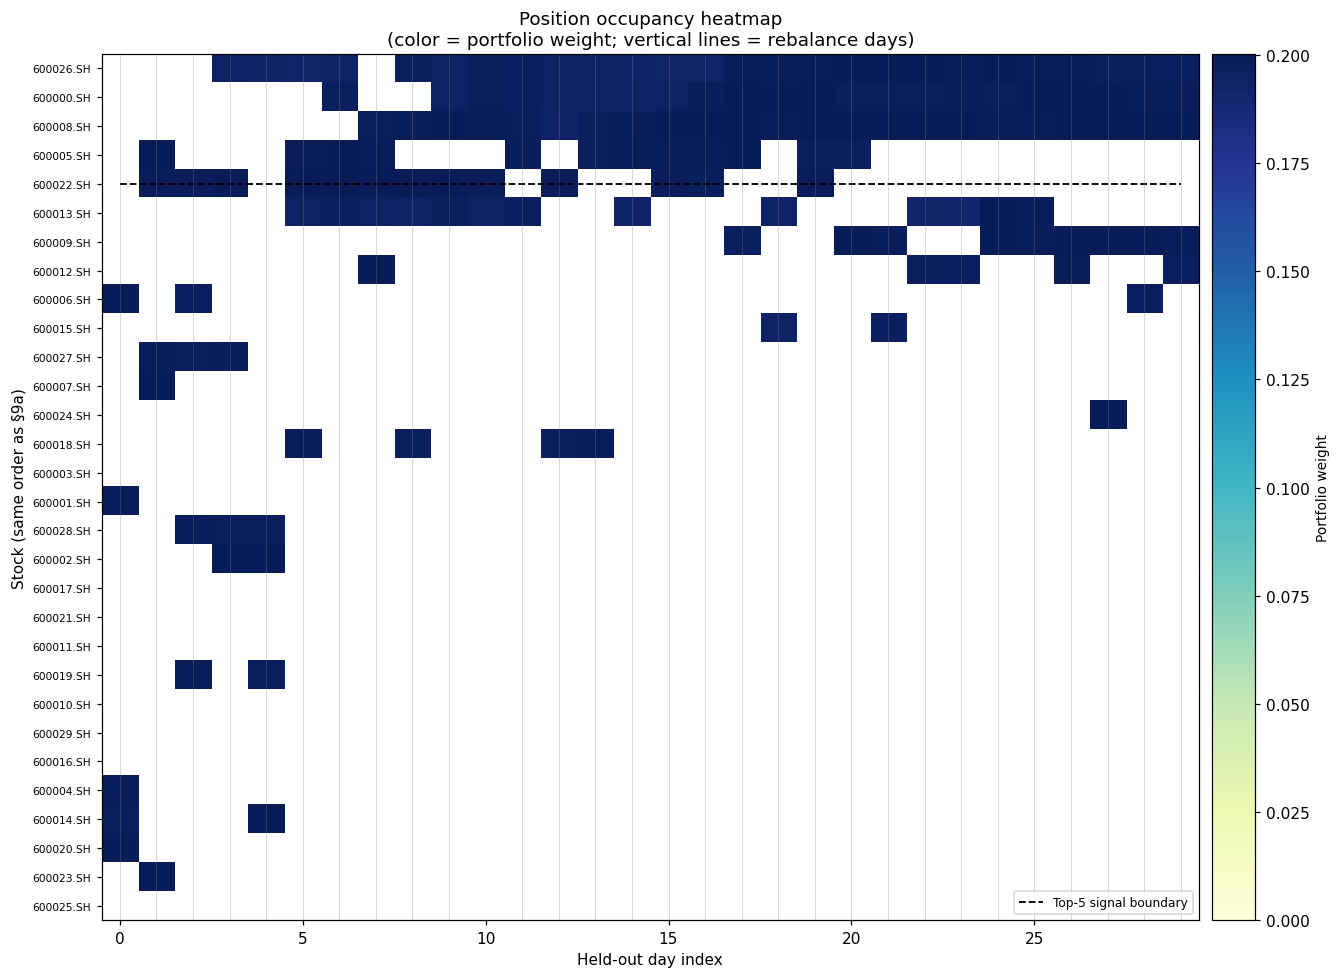

Mean daily weight turnover: 0.5772  (~57.7% of portfolio rebalanced per day)
Stocks ever held: 22 / 30
Median holding days: 3


In [39]:
weight_ordered = weight_matrix[:, order]  # same row order as §9a

fig, ax = plt.subplots(figsize=(13, 9))
# Use a masked array so zero-weight cells render as white/background.
masked = np.ma.masked_where(weight_ordered.T == 0, weight_ordered.T)
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad(color="white")
vmax_w = max(weight_matrix.max(), 1e-6)
im = ax.imshow(masked, aspect="auto", cmap=cmap, vmin=0, vmax=vmax_w,
               interpolation="nearest",
               extent=[-0.5, len(held_out) - 0.5, len(all_syms) - 0.5, -0.5])

# Overlay the top-5 boundary from §9a for direct comparison.
ax.plot(range(len(held_out)), boundary_y, "k--", linewidth=1.2,
        label="Top-5 signal boundary")

# Mark rebalance days (days with any trade) with vertical grid lines.
rebal_days = [t for t, d in enumerate(held_out)
              if any(tr.date == d for tr in pm.trades)]
for t in rebal_days:
    ax.axvline(t, color="gray", linewidth=0.4, alpha=0.5)

ax.set_yticks(range(len(syms_ordered)))
ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_ylabel("Stock (same order as §9a)")
ax.set_xlabel("Held-out day index")
ax.set_title("Position occupancy heatmap\n(color = portfolio weight; vertical lines = rebalance days)")
ax.legend(loc="lower right", fontsize=8)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Portfolio weight", fontsize=9)
plt.tight_layout()
plt.show()

# Quantify turnover: mean day-to-day weight change (excludes entry/exit edges).
turnover = np.abs(np.diff(weight_matrix, axis=0)).sum(axis=1).mean()
print(f"Mean daily weight turnover: {turnover:.4f}  "
      f"(~{turnover*100:.1f}% of portfolio rebalanced per day)")
print(f"Stocks ever held: {int((weight_matrix > 0).any(axis=0).sum())} / {len(all_syms)}")
print(f"Median holding days: "
      f"{np.median([(weight_matrix[:, i] > 0).sum() for i in range(len(all_syms)) if (weight_matrix[:, i] > 0).any()]):.0f}")

### Trade-by-trade breakdown

Each trade shows the A-share cost breakdown (commission + stamp duty on sells).

In [40]:
print(f"{'#':>3}  {'Date':>10}  {'Symbol':<12}  {'Dir':<8}  {'Qty':>8}  {'Price':>8}  {'Cost':>8}  {'Reason':<14}")
print("-" * 88)
for i, t in enumerate(pm.trades[:25]):
    print(f"{i+1:>3}  {t.date:>10}  {t.symbol:<12}  {t.direction:<8}  "
          f"{t.quantity:>+8.0f}  {t.price:>8.2f}  {t.cost:>8.2f}  {t.reason:<14}")
if len(pm.trades) > 25:
    print(f"  ... and {len(pm.trades) - 25} more trades")

  #        Date  Symbol        Dir            Qty     Price      Cost  Reason        
----------------------------------------------------------------------------------------
  1    20200321  600001.SH     OPEN         +7100     28.00     53.68  REBALANCE     
  2    20200321  600004.SH     OPEN         +8600     23.05     53.51  REBALANCE     
  3    20200321  600020.SH     OPEN        +13700     14.59     53.97  REBALANCE     
  4    20200321  600014.SH     OPEN         +6800     29.06     53.35  REBALANCE     
  5    20200321  600006.SH     OPEN         +4000     49.97     53.97  REBALANCE     
  6    20200322  600001.SH     CLOSE        -7100     28.32    255.35  REBALANCE     
  7    20200322  600004.SH     CLOSE        -8600     22.79    248.88  REBALANCE     
  8    20200322  600020.SH     CLOSE       -13700     14.74    256.39  REBALANCE     
  9    20200322  600014.SH     CLOSE        -6800     28.77    248.48  REBALANCE     
 10    20200322  600006.SH     CLOSE        -4000  

---

## 10. Risk Management — A-share Pre-trade & Post-bar Controls

The `RiskManager` sits between the `PortfolioManager` and `Portfolio.apply_trade`. It enforces both **A-share structural rules** (T+1, price-limit lock, board lot, concentration) and **portfolio-level monitors** (stop-loss, drawdown, daily-loss limit).

### Pre-trade rules

| Rule | Config field | Behaviour |
|------|-------------|-----------|
| T+1 settlement | `enforce_t1` | Shrinks sells to `available_qty` (= qty − t1_locked) |
| Price-limit lock | `reject_limit_locked` | Reject buys at limit-up, sells at limit-down |
| Board lot | `enforce_lot` | Round buys down to multiples of 100 shares |
| Concentration | `max_weight_per_name` | Shrink buys so post-trade weight ≤ cap |
| Notional cap | `max_notional_per_trade` | Shrink any trade exceeding yuan limit |
| Order frequency | `max_trades_per_day` | Reject once per-day cap hit |
| Circuit breaker | `halted` flag | Reject new OPENs when halted (closes still allowed) |
| Suspension | `reject_suspended` | Reject all trades on halted symbols |

### Post-bar monitors

| Monitor | Config field | Trigger |
|---------|-------------|---------|
| Stop loss | `stop_loss_pct` | Per-position unrealized loss > pct of cost |
| Take profit | `take_profit_pct` | Per-position unrealized profit > pct of cost |
| Max drawdown | `max_drawdown_pct` | Equity drops from peak by pct → halt + liquidate |
| Daily loss limit | `daily_loss_limit_pct` | Daily realized loss > pct of capital → halt + liquidate |

In [19]:
# Configure A-share risk rules
risk_cfg = RiskConfig(
    enforce_t1=True,
    enforce_lot=True,
    reject_limit_locked=True,
    reject_suspended=True,
    max_weight_per_name=0.25,        # max 25% in any single stock
    max_notional_per_trade=200_000,  # max 200k yuan per trade
    max_trades_per_day=20,
    stop_loss_pct=0.08,              # cut losers at -8%
    take_profit_pct=None,            # let winners run
    max_drawdown_pct=0.15,           # halt at -15% from peak
    daily_loss_limit_pct=0.03,       # halt at -3% daily realized loss
)

pm_risk = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    weighting="equal",
    aggregator=SignalAggregator(calibration=result),
    risk_manager=RiskManager(risk_cfg, initial_capital=1_000_000.0),
)
live_engine_risk = TradingEngine(calibration=result)

equity_risk, npos_risk = [], []
for d in held_out:
    sigs = live_engine_risk.on_cross_section(d, bars_full[d])
    pm_risk.decide(d, bars_full[d], sigs)
    equity_risk.append(pm_risk.portfolio.mark_to_market(bars_full[d]))
    npos_risk.append(sum(1 for p in pm_risk.portfolio.positions.values() if p.quantity > 0))

print(f"With risk:    final equity = {equity_risk[-1]:,.0f}  "
      f"return = {(equity_risk[-1]/1e6-1)*100:+.2f}%  trades = {len(pm_risk.trades)}")
print(f"Without risk: final equity = {equity_hist[-1]:,.0f}  "
      f"return = {(equity_hist[-1]/1e6-1)*100:+.2f}%  trades = {len(pm.trades)}")

With risk:    final equity = 1,102,574  return = +10.26%  trades = 146
Without risk: final equity = 1,102,084  return = +10.21%  trades = 121


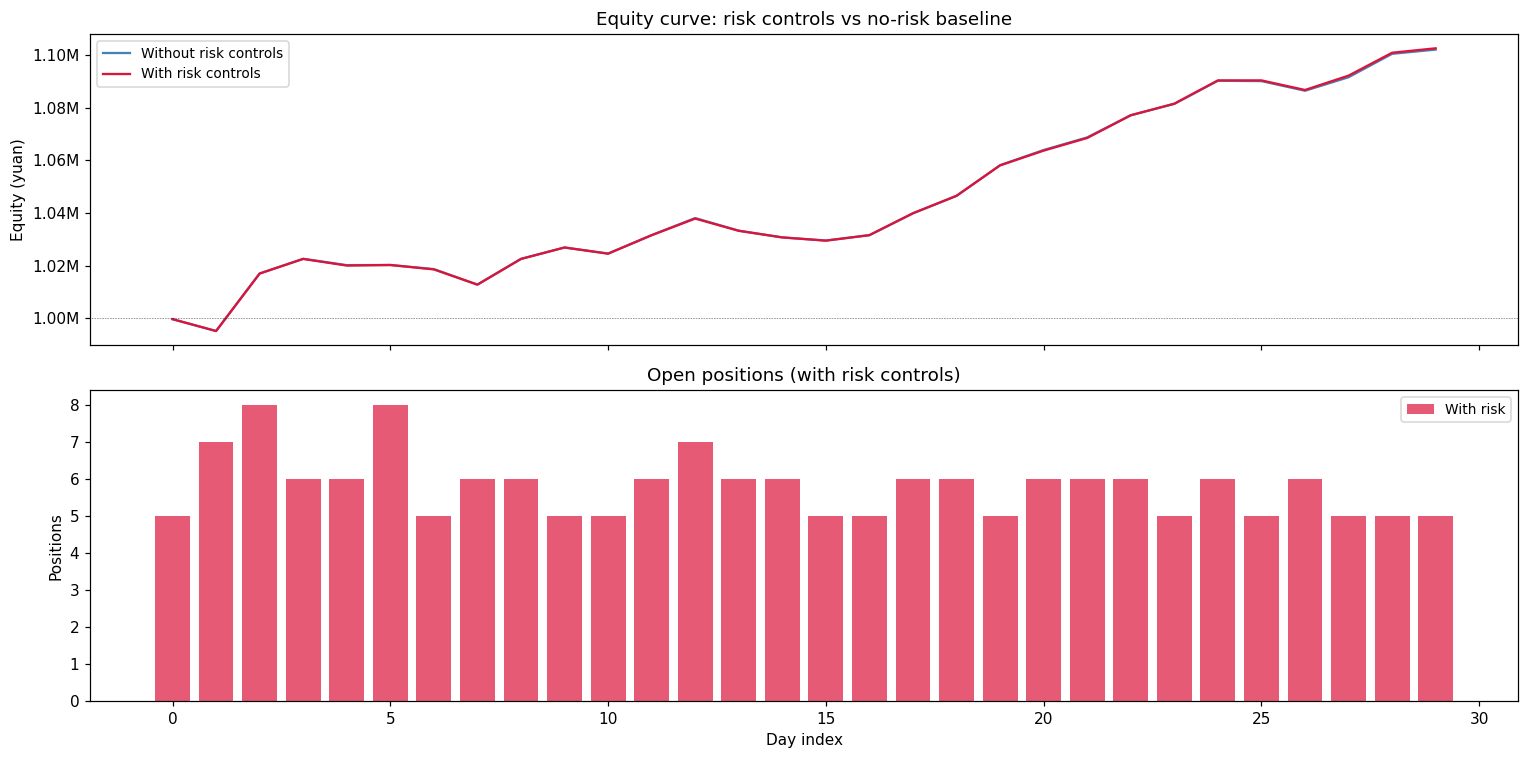

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
x = range(len(held_out))

axes[0].plot(x, equity_hist, linewidth=1.5, color="steelblue", label="Without risk controls")
axes[0].plot(x, equity_risk, linewidth=1.5, color="crimson", label="With risk controls")
axes[0].axhline(1_000_000, color="k", linewidth=0.4, linestyle=":")
axes[0].set_ylabel("Equity (yuan)")
axes[0].set_title("Equity curve: risk controls vs no-risk baseline")
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))

axes[1].bar(x, npos_risk, color="crimson", alpha=0.7, label="With risk")
axes[1].set_ylabel("Positions")
axes[1].set_xlabel("Day index")
axes[1].set_title("Open positions (with risk controls)")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

### Risk-triggered trades

Trades with `STOP_LOSS`, `TAKE_PROFIT`, `MAX_DRAWDOWN`, or `DAILY_LOSS_LIMIT` reasons are forced by the post-bar monitor, not by signals.

In [21]:
risk_trades = [t for t in pm_risk.trades
               if t.reason in ("STOP_LOSS", "TAKE_PROFIT", "MAX_DRAWDOWN", "DAILY_LOSS_LIMIT")]
print(f"Risk-triggered trades: {len(risk_trades)}")
for t in risk_trades[:10]:
    print(f"  {t}")
if pm_risk.risk.halted:
    print(f"\n⚠ System halted (drawdown or daily-loss limit breached)")

Risk-triggered trades: 0


### 10a. Circuit breaker demonstration

With a very tight drawdown limit, the system halts early and blocks all new opens for the rest of the run.

In [22]:
tight_cfg = RiskConfig(
    max_weight_per_name=0.25,
    stop_loss_pct=0.05,
    max_drawdown_pct=0.03,        # halt at just -3% from peak
    daily_loss_limit_pct=0.02,
    max_notional_per_trade=None,
    max_trades_per_day=None,
)

pm_tight = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    aggregator=SignalAggregator(calibration=result),
    risk_manager=RiskManager(tight_cfg, initial_capital=1_000_000.0),
)
eng_tight = TradingEngine(calibration=result)

halt_date = None
for d in held_out:
    pm_tight.decide(d, bars_full[d], eng_tight.on_cross_section(d, bars_full[d]))
    if pm_tight.risk.halted and halt_date is None:
        halt_date = d
        eq = pm_tight.portfolio.mark_to_market(bars_full[d])
        print(f"Halted on {d} at equity {eq:,.0f} "
              f"(return {(eq/1e6-1)*100:+.2f}%)")
        break

if halt_date is None:
    print("System did not halt with the tight config on this run.")

System did not halt with the tight config on this run.


### 10b. Verifying A-share structural constraints

After a full run, verify that the portfolio never violated T+1, never went short, and all buys were in 100-share lots.

In [23]:
# Re-run the full pipeline and check all A-share constraints
pm_check = PortfolioManager(
    capital=1_000_000.0,
    n_holdings=5,
    aggregator=SignalAggregator(calibration=result),
)
eng_check = TradingEngine(calibration=result)

for d in held_out:
    pm_check.decide(d, bars_full[d], eng_check.on_cross_section(d, bars_full[d]))

# 1. Long-only: no position ever went negative
any_short = any(p.quantity < 0 for p in pm_check.portfolio.positions.values())

# 2. Board lot: every buy is a multiple of 100
bad_lots = [t for t in pm_check.trades if t.quantity > 0 and int(t.quantity) % 100 != 0]

# 3. T+1: no symbol was bought and sold on the same date
from collections import defaultdict
day_sym = defaultdict(set)
for t in pm_check.trades:
    if t.quantity > 0:
        day_sym[(t.date, t.symbol)].add("B")
    elif t.quantity < 0:
        day_sym[(t.date, t.symbol)].add("S")
t1_violations = [k for k, v in day_sym.items() if v == {"B", "S"}]

# 4. No trades on suspended or limit-locked bars
bad_limit = []
for t in pm_check.trades:
    bar = bars_full[t.date].get(t.symbol)
    if bar is None:
        continue
    if t.quantity > 0 and bar.is_limit_up:
        bad_limit.append((t, "buy at limit_up"))
    if t.quantity < 0 and bar.is_limit_down:
        bad_limit.append((t, "sell at limit_down"))

print("A-share constraint check:")
print(f"  Long-only (no shorts):     {'PASS' if not any_short else 'FAIL'}")
print(f"  Board lot (100 multiples): {'PASS' if not bad_lots else 'FAIL'} ({len(bad_lots)} violations)")
print(f"  T+1 (no same-day B+S):     {'PASS' if not t1_violations else 'FAIL'} ({len(t1_violations)} violations)")
print(f"  Limit-lock respected:      {'PASS' if not bad_limit else 'FAIL'} ({len(bad_limit)} violations)")

A-share constraint check:
  Long-only (no shorts):     PASS
  Board lot (100 multiples): PASS (0 violations)
  T+1 (no same-day B+S):     PASS (0 violations)
  Limit-lock respected:      PASS (0 violations)


---

## 11. Full Calibrated Pipeline — Summary

The complete alftrade workflow in one cell:

```python
# 1. Generate (or load) a daily OHLCV panel
bars, uni = generate_simulated_market(n_stocks=30, n_days=250)

# 2. Calibrate (Fama-MacBeth Ridge, offline phase)
engine = TradingEngine()
cal = FactorCalibrator(horizon=5, alpha=1.0)
for d in train_dates:
    cal.collect(d, engine.build_cross_section(d, bars[d]), bars)
result = cal.fit()                          # → CalibrationResult

# 3. Trade (online phase, calibrated signals)
live = TradingEngine(calibration=result)
pm = PortfolioManager(capital=1e6, n_holdings=5,
                      aggregator=SignalAggregator(calibration=result))
for d in test_dates:
    sigs = live.on_cross_section(d, bars[d])
    pm.decide(d, bars[d], sigs)             # → [Trade], portfolio updated
```

**Key takeaways:**
- **Signal frequency = daily.** `on_cross_section` runs at most once per trading day per stock — no intraday signals.
- **Cross-sectional, not time-series.** Factors are z-scored within each day's universe; β comes from Fama-MacBeth (per-date regressions averaged over time).
- **A-share frictions are first-class.** T+1, price-limit lock, board lot, and commission+stamp-duty costs are enforced in the risk and cost layers, not bolted on.
- **Pure Python.** No C++/Cython build step — daily frequency doesn't need it.

In [24]:
# Final summary
print("=== alftrade demo summary ===")
print(f"Panel:           {len(uni_full.symbols)} stocks × {len(dates_full)} days")
print(f"Calibration:     Fama-MacBeth, T={result.n_dates} dates, n={result.sample_size} pairs")
print(f"Model IC:        {model_profile.model_ic:+.4f}")
print(f"Model mono:      {model_profile.model_monotonicity:+.4f}")
print(f"Significant (p<0.05): {model_profile.selected_factors()}")
print(f"Backtest:        {len(held_out)} held-out days, 5 holdings, equal-weight")
print(f"  Without risk:  return = {(equity_hist[-1]/1e6-1)*100:+.2f}%, trades = {len(pm.trades)}")
print(f"  With risk:     return = {(equity_risk[-1]/1e6-1)*100:+.2f}%, trades = {len(pm_risk.trades)}")

=== alftrade demo summary ===
Panel:           30 stocks × 250 days
Calibration:     Fama-MacBeth, T=215 dates, n=6450 pairs
Model IC:        +0.2905
Model mono:      +1.0000
Significant (p<0.05): ['volatility_20d', 'rsi_14', 'atr_pct_14']
Backtest:        30 held-out days, 5 holdings, equal-weight
  Without risk:  return = +10.21%, trades = 121
  With risk:     return = +10.26%, trades = 146
